# Student Performance Indicator

# Life Cycle of Machine Learning Project

1. Understanding the Problem Statement  
2. Data Collection  
3. Data Checks to Perform  
4. Exploratory Data Analysis  
5. Data Pre-Processing  
6. Model Training  
7. Choose Best Model



# Student Performance Indicator

## 1) Problem Statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch, and Test preparation course.

## 2) Data Collection
- Dataset Source: [Kaggle - Students Performance in Exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977)
- The data consists of 8 columns and 1000 rows.

### 2.1 Import Data and Required Packages
Importing **Pandas**, **NumPy**, **Matplotlib**, **Seaborn**, and **Warnings** library.



In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

Import the CSV Data as Pandas DataFrame

In [139]:
import os
os.getcwd()

'D:\\mlproject'

In [110]:
# import os
# os.chdir('D:/mlproject/')
df = pd.read_csv('src/notebook/data/StudentsPerformance.csv')


Show Top 5 Records

In [111]:
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Shape of the Dataset

In [112]:
df.shape

(1000, 8)

## 2.2 Dataset Information

- **gender** : sex of students → (Male/Female)  
- **race/ethnicity** : ethnicity of students → (Group A, B, C, D, E)  
- **parental level of education** : parents' final education → (bachelor's degree, some college, master's degree, associate's degree, high school)  
- **lunch** : having lunch before test → (standard or free/reduced)  
- **test preparation course** : complete or not complete before test  
- **math score**  
- **reading score**  
- **writing score**

---

## 3. Data Checks to Perform
- Check Missing values  
- Check Duplicates  
- Check Data Type  
- Check the number of unique values of each column  
- Check statistics of dataset  
- Check various categories present in the different categorical columns

##  3.1 Check Missing Values


In [113]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

There is no missing values in the dataset.

##  3.2 Check Duplicates

In [114]:
df.duplicated().sum()

np.int64(0)

There is no duplicate values in the dataset

##  3.3  Check Datatypes

In [115]:
#Check Null and Dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


##  3.4 Checking the number of unique values of each column

In [116]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

##  3.5 Check statistics of data set

In [117]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



## Insight
- From above description of numerical data, all means are very close to each other — between **66 and 68.05**.  
- All standard deviations are also close — between **14.6 and 15.19**.  
- While there is a minimum score **0 for math**, for writing minimum is much higher (**10**) and for reading even higher (**17**).

---

### 3.7 Exploring Data

In [118]:
print("Categories in  'gender' variable :", end=" ")
print(df['gender'].unique())
print("Categories in  'race/ethnicity' variable :", end=" ")
print(df['race/ethnicity'].unique())
print("Categories in  'parental level of education' variable :", end=" ")
print(df['parental level of education'].unique())
print("Categories in  'lunch' variable :", end=" ")
print(df['lunch'].unique())
print("Categories in  'test preparation course' variable :", end=" ")
print(df['test preparation course'].unique())


Categories in  'gender' variable : ['female' 'male']
Categories in  'race/ethnicity' variable : ['group B' 'group C' 'group A' 'group D' 'group E']
Categories in  'parental level of education' variable : ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
Categories in  'lunch' variable : ['standard' 'free/reduced']
Categories in  'test preparation course' variable : ['none' 'completed']


In [119]:
#define numerical features and categorical features
numerical_features = df.select_dtypes(['int64','float64']).columns.tolist()
categorical_features = df.select_dtypes(['object']).columns.tolist()

print("Numerical Features: ", numerical_features)
print("Categorical Features: ", categorical_features)

Numerical Features:  ['math score', 'reading score', 'writing score']
Categorical Features:  ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


## 3.8 Adding columns for "Total Score" and "Average"

In [120]:

total_scores=df['math score'] + df['reading score'] +df['writing score']
df['average score']=round(total_scores/3,2)
df['total scores']=total_scores
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average score,total scores
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67,218
1,female,group C,some college,standard,completed,69,90,88,82.33,247
2,female,group B,master's degree,standard,none,90,95,93,92.67,278
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33,148
4,male,group C,some college,standard,none,76,78,75,76.33,229


In [121]:
##count of students who score full marks
reading_full=df[df['reading score']==100]['average score'].count()
math_full=df[df['math score']==100]['average score'].count()
writing_full=df[df['writing score']==100]['average score'].count()


print("Count of students who scored full marks in reading: ", reading_full)
print("Count of students who scored full marks in math: ", math_full)
print("Count of students who scored full marks in writing: ", writing_full)


Count of students who scored full marks in reading:  17
Count of students who scored full marks in math:  7
Count of students who scored full marks in writing:  14


In [122]:
#Student count who are scored under 20

reading_less_20=df[df['reading score'] <= 20]['average score'].count()
math_less_20=df[df['math score'] <= 20]['average score'].count()
writing_less_20=df[df['writing score'] <= 20]['average score'].count()

print("Count of students who scored under 20 in reading: ", reading_less_20)
print("Count of students who scored under 20 in math: ", math_less_20)
print("Count of students who scored under 20 in writing: ", writing_less_20)

Count of students who scored under 20 in reading:  1
Count of students who scored under 20 in math:  4
Count of students who scored under 20 in writing:  3



## Insights
- From the above values, we observe that students have performed the **worst in Mathematics**.
- The **best performance** is observed in the **Reading section**.

---

## 4. Exploring Data (Visualization)

### 4.1 Visualize Average Score Distribution to Make Some Conclusion
We will use the following plots to understand the distribution of average scores:
- **Histogram**
- **Kernel Distribution Function (KDE)**

---

### 4.1.1 Histogram & KDE
Visualize the average score distribution using both Histogram and KDE to identify patterns and insights.

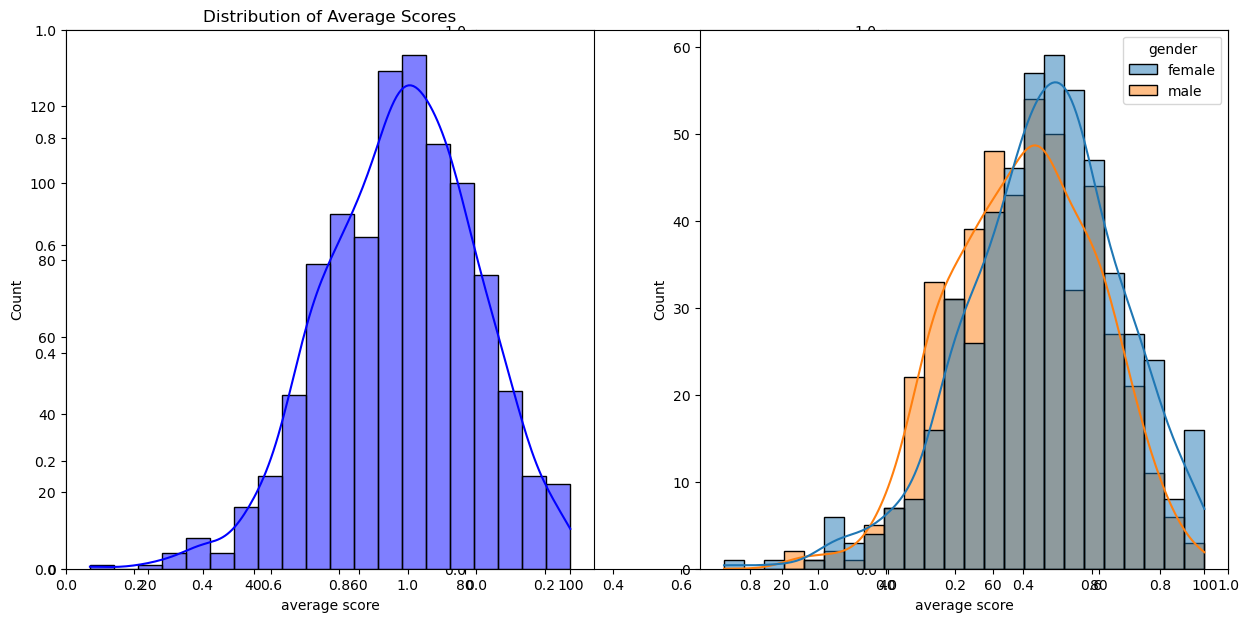

In [123]:
fig,ax=plt.subplots(1,3,figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='average score',bins=20,kde=True,color='b')
plt.title('Distribution of Average Scores')
plt.subplot(122)
sns.histplot(data=df,x='average score',hue='gender',kde=True)
plt.show()

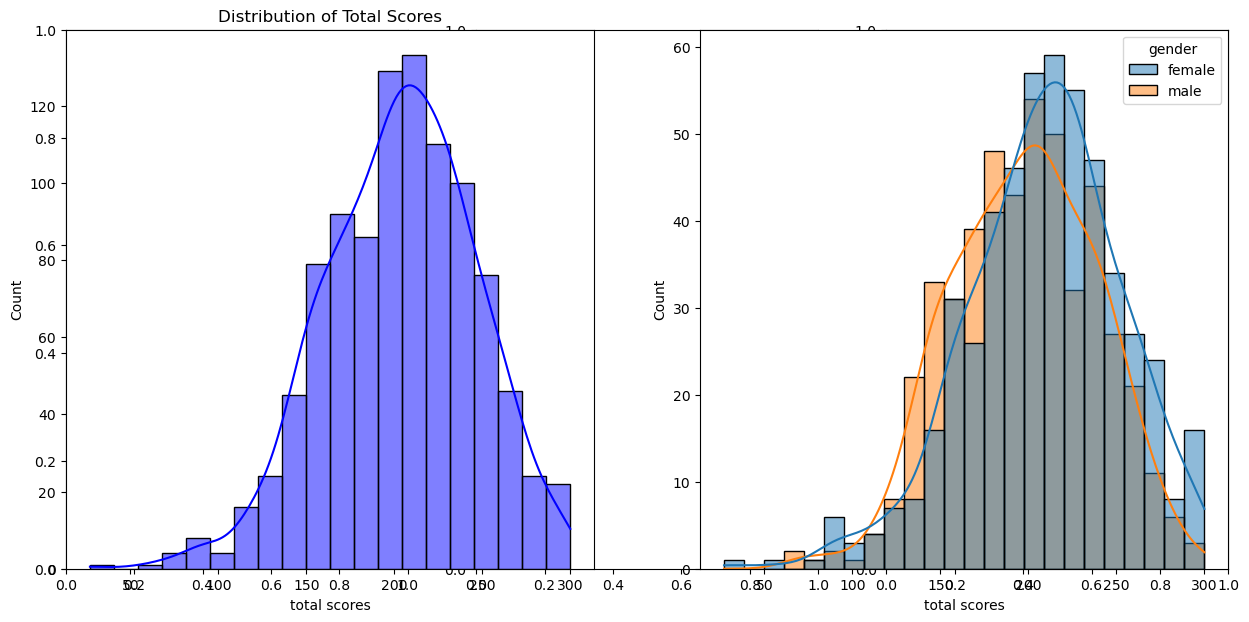

In [124]:
fig,ax=plt.subplots(1,3,figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='total scores',bins=20,kde=True,color='b')
plt.title('Distribution of Total Scores')
plt.subplot(122)
sns.histplot(data=df,x='total scores',hue='gender',kde=True)
plt.show()

# Insights

- Female students tend to perform well than male students

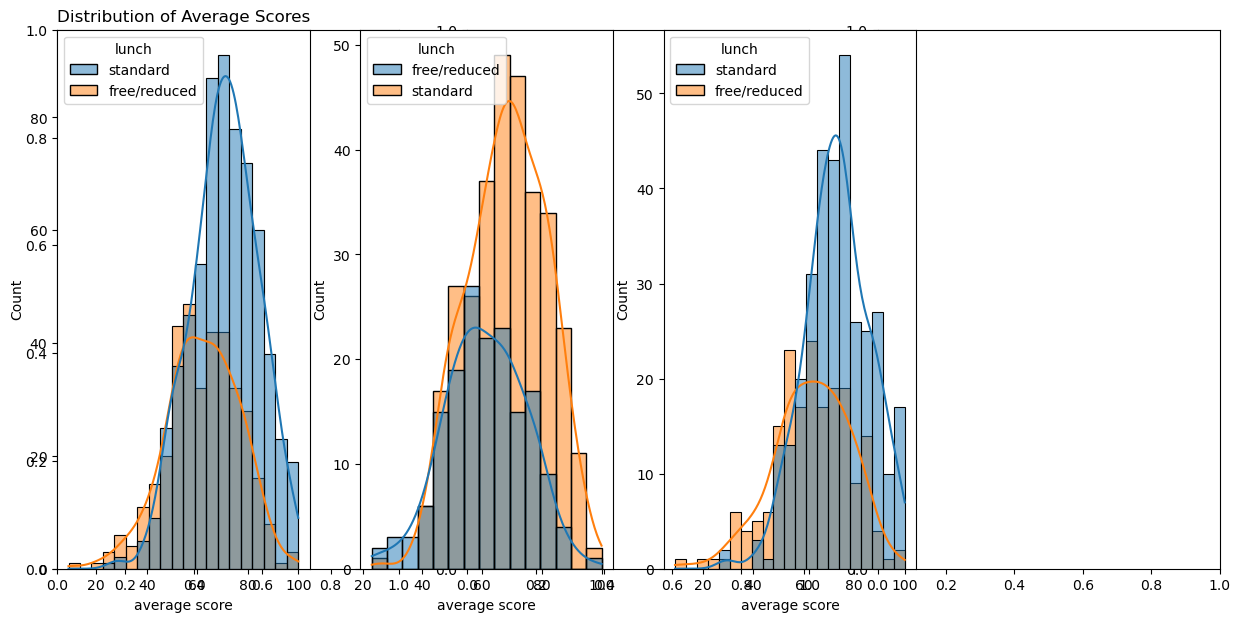

In [125]:
plt.subplots(1,3,figsize=(15,7))
plt.subplot(141)
sns.histplot(data=df,x='average score',bins=20,kde=True,color='b',hue='lunch')
plt.title('Distribution of Average Scores')
plt.subplot(142)
sns.histplot(data=df[df.gender == 'male'],x='average score',hue='lunch',kde=True)
plt.subplot(143)
sns.histplot(data=df[df.gender == 'female'],x='average score',hue='lunch',kde=True)

plt.show()

# Insights

- Standard lunch helps perform well in exams.
- Standard lunch helps perform well in exams be it a male or female students.

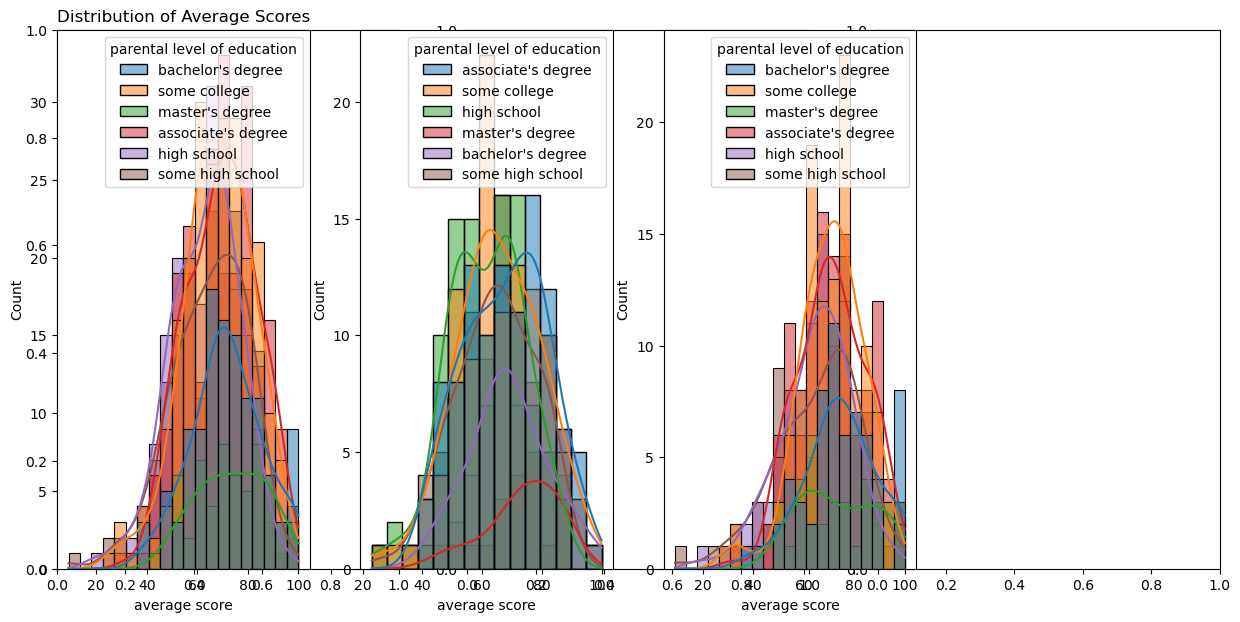

In [126]:
fig,ax=plt.subplots(1,3,figsize=(15,7))
plt.subplot(141)
sns.histplot(data=df,x='average score',bins=20,kde=True,color='b',hue='parental level of education')
plt.title('Distribution of Average Scores')
plt.subplot(142)
sns.histplot(data=df[df.gender == 'male'],x='average score',hue='parental level of education',kde=True)
plt.subplot(143)
sns.histplot(data=df[df.gender == 'female'],x='average score',hue='parental level of education',kde=True)
plt.show()

## Insights

- In general, parent's education doesn't help students perform well in exams.  
- The second plot shows that parents whose education is an **associate's degree** or **master's degree** have **male children** who tend to perform better in exams.  
- From the third plot, we can see that there is **no significant effect** of parent's education on **female students**.


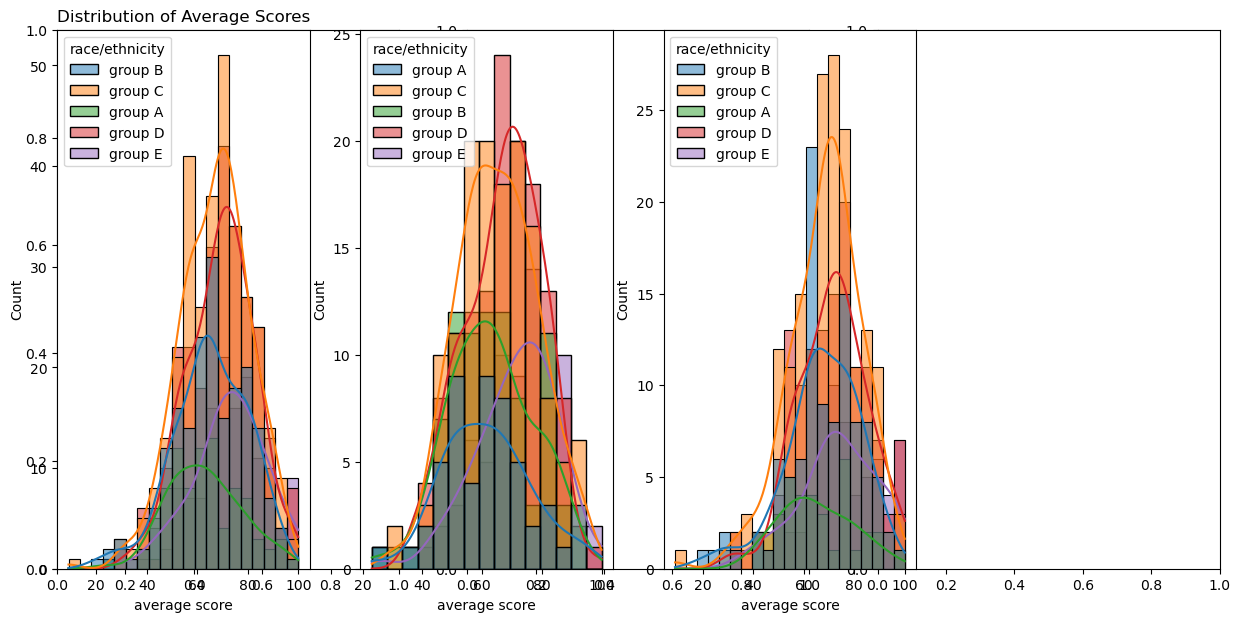

In [127]:
fig,ax=plt.subplots(1,3,figsize=(15,7))
plt.subplot(141)
sns.histplot(data=df,x='average score',bins=20,kde=True,color='b',hue='race/ethnicity')
plt.title('Distribution of Average Scores')
plt.subplot(142)
sns.histplot(data=df[df.gender == 'male'],x='average score',hue='race/ethnicity',kde=True)
plt.subplot(143)
sns.histplot(data=df[df.gender == 'female'],x='average score',hue='race/ethnicity',kde=True)
plt.show()

## Insights

- Students of **Group A** and **Group B** tend to perform poorly in exams.  
- Students of **Group A** and **Group B** perform poorly in exams **irrespective of gender** (both male and female).

---

## 4.2 Maximum Score of Students in All Three Subjects


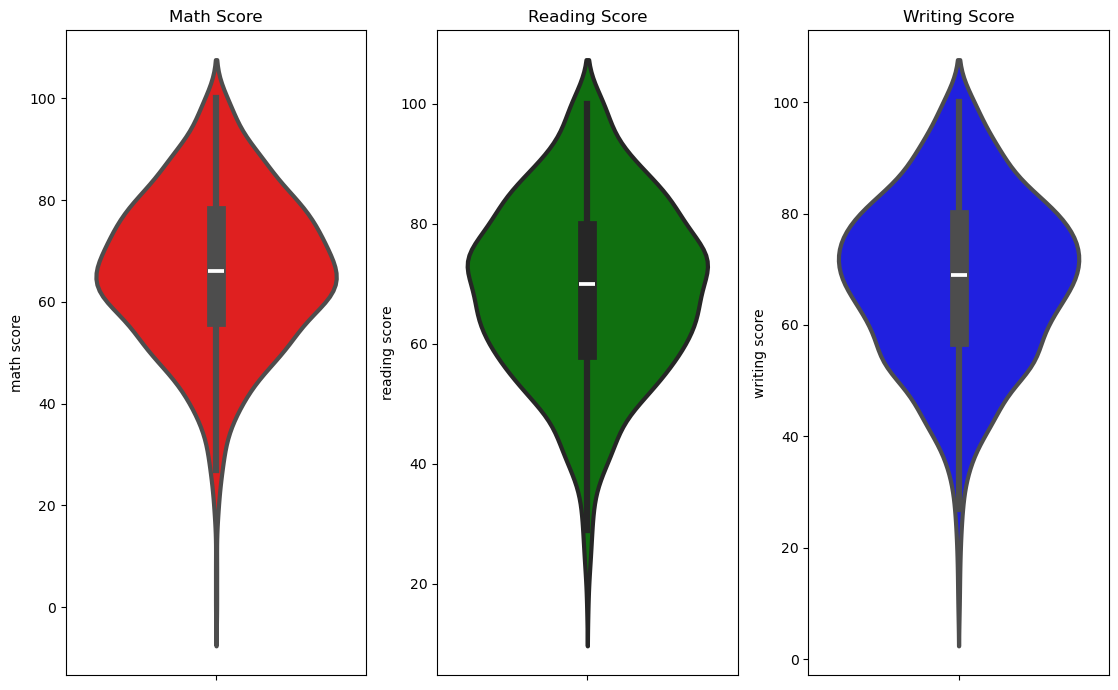

In [128]:
plt.figure(figsize=(15,7))
plt.subplot(1,4,1)
plt.title('Math Score')
sns.violinplot(data=df,y='math score',color='red',linewidth=3)
plt.subplot(1,4,2)
plt.title('Reading Score')
sns.violinplot(data=df,y='reading score',color='green',linewidth=3)
plt.subplot(1,4,3)
plt.title('Writing Score')
sns.violinplot(data=df,y='writing score',color='blue',linewidth=3)
plt.tight_layout()
plt.show()


## Insights

- From the above three plots, it is clearly visible that most of the students score between **60–80** in **Maths**,  
  whereas in **Reading** and **Writing**, most of them score between **50–80**.

---

## 4.3 Bivariate Analysis 


### 4.3.1 Comparison of Student Scores by Gender

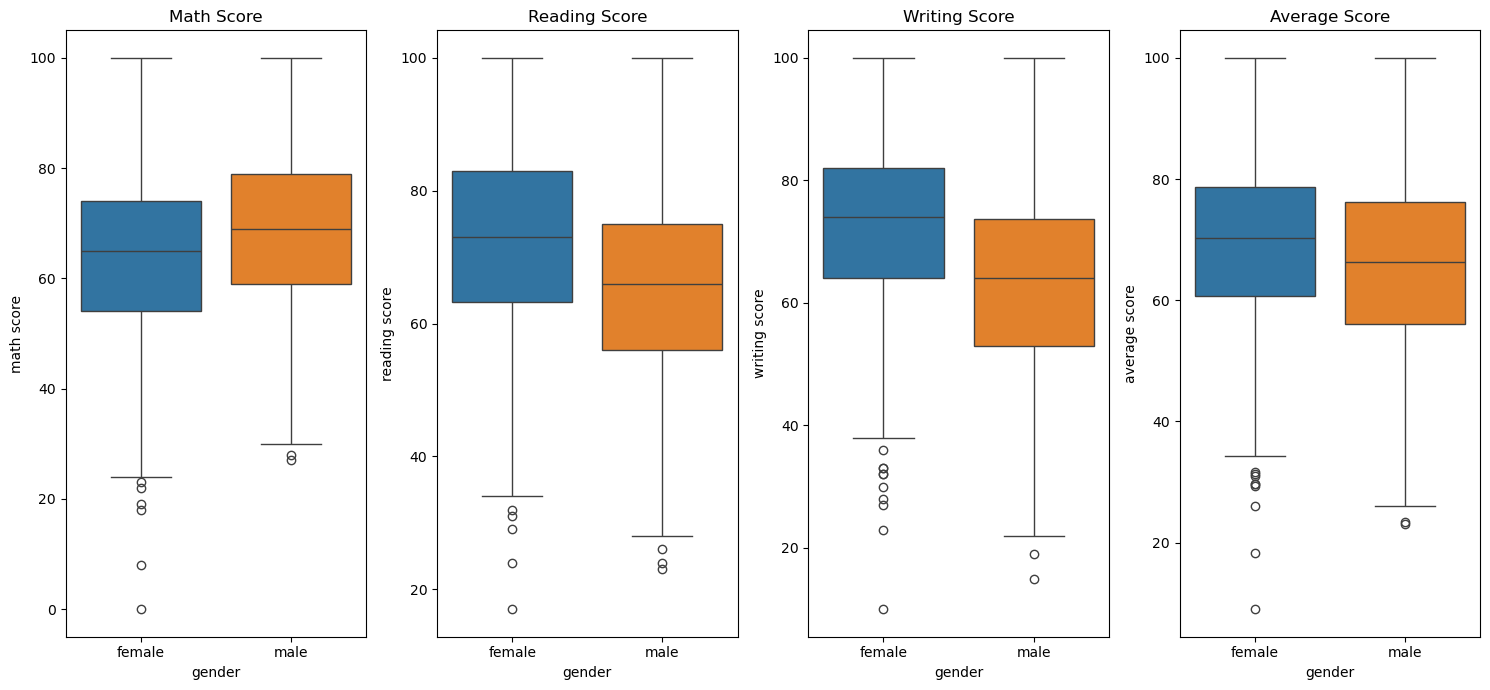

In [129]:
plt.figure(figsize=(15,7))
plt.subplot(1,4,1)
sns.boxplot(data=df,x='gender',y='math score',hue='gender')
plt.title('Math Score')
plt.subplot(1,4,2)
sns.boxplot(data=df,x='gender',y='reading score',hue='gender')
plt.title('Reading Score')
plt.subplot(1,4,3)
sns.boxplot(data=df,x='gender',y='writing score',hue='gender')
plt.title('Writing Score')
plt.subplot(1,4,4)
sns.boxplot(data=df,x='gender',y='average score',hue='gender')
plt.title('Average Score')
plt.tight_layout()
plt.show()

## Insights 

- **Math Score**
  - Both groups show similar median scores.
  - The blue group has slightly higher variability (wider interquartile range).
  - A few low outliers are present, indicating some students performed poorly.

- **Reading Score**
  - The blue group performs better overall, with a higher median.
  - The orange group’s scores are more spread out, suggesting inconsistent performance.
  - Outliers exist at the lower end for both groups.

- **Writing Score**
  - The blue group again shows higher median scores.
  - The orange group’s distribution is lower and more variable.
  - Several low outliers indicate weaker writing performance among some students.

- **Average Score**
  - The blue group has a higher median average score.
  - The orange group’s average is slightly lower, with more spread.
  - Outliers in the lower range suggest a few students consistently underperformed across subjects.



### 4.3.2 Comparison of Average Scores by Lunch, Parental level of Education, race/ethnicity

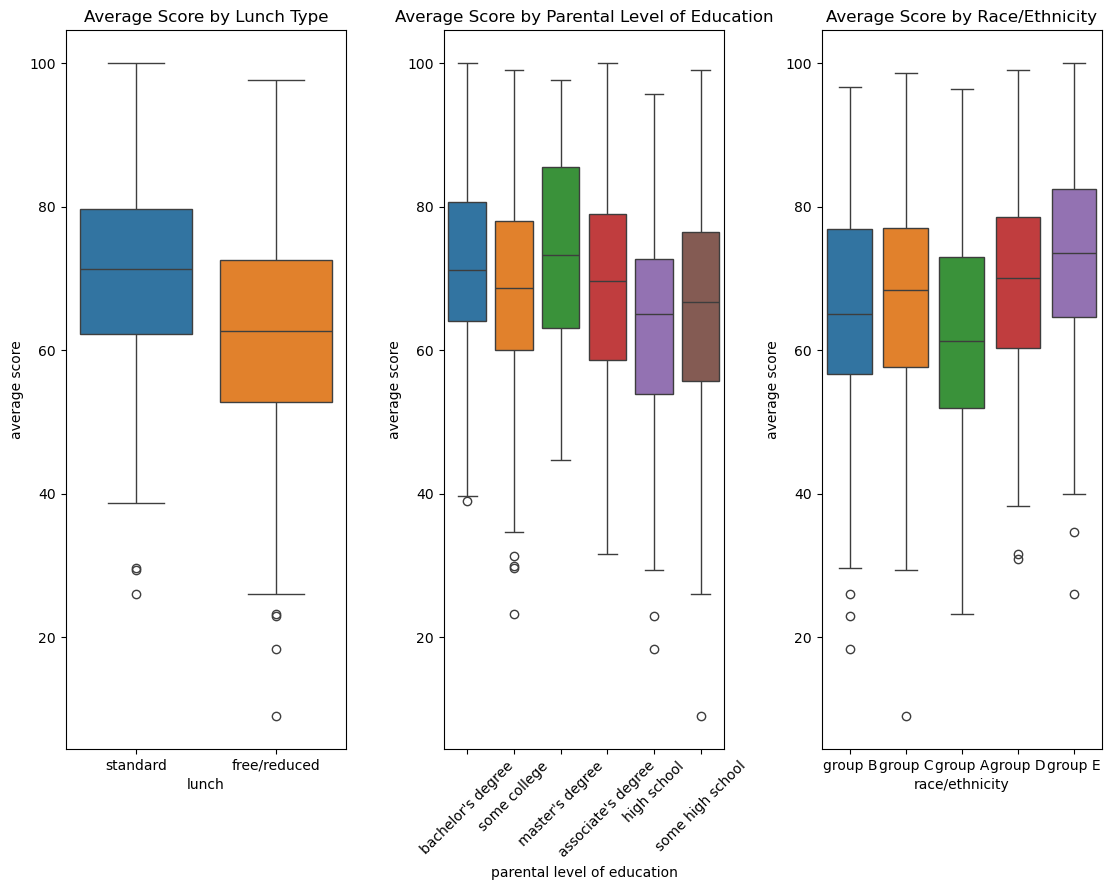

In [130]:
plt.figure(figsize=(15,9))
plt.subplot(1,4,1)
sns.boxplot(data=df,x='lunch',y='average score',hue='lunch')
plt.title('Average Score by Lunch Type')
plt.subplot(1,4,2)
sns.boxplot(data=df,x='parental level of education',y='average score',hue='parental level of education')
plt.title('Average Score by Parental Level of Education')
plt.xticks(rotation=45)
plt.subplot(1,4,3)
sns.boxplot(data=df,x='race/ethnicity',y='average score',hue='race/ethnicity')
plt.title('Average Score by Race/Ethnicity')



plt.tight_layout()
plt.show()

## Insights from Box Plots

### 1. Average Score by Lunch Type
- Students who had **standard lunch** performed **better on average** than those who had **free/reduced lunch**.
- The median score for the standard lunch group is higher, indicating better overall performance.
- The free/reduced lunch group shows **greater variability** and more **low outliers**, suggesting socioeconomic factors may influence academic outcomes.

---

### 2. Average Score by Parental Level of Education
- Students whose parents have a **master’s or bachelor’s degree** tend to score **higher on average**.
- The **lowest median scores** are observed among students whose parents have **some high school** education.
- This trend suggests a **positive correlation between parental education and student performance**.
- Outliers at the lower end indicate that even within higher education groups, some students underperform.

---

### 3. Average Score by Race/Ethnicity
- There are **visible differences** in median scores among racial/ethnic groups.
- The **purple group** (likely Group E) shows the **highest median average score**, while the **green group** (Group C) has the **lowest**.
- The spread of scores is similar across groups, but the **performance gap** between groups is noticeable.
- This may reflect **differences in educational access or support systems

### 4.3.3 Comparision between Math Score, Reading Score, Writing Score

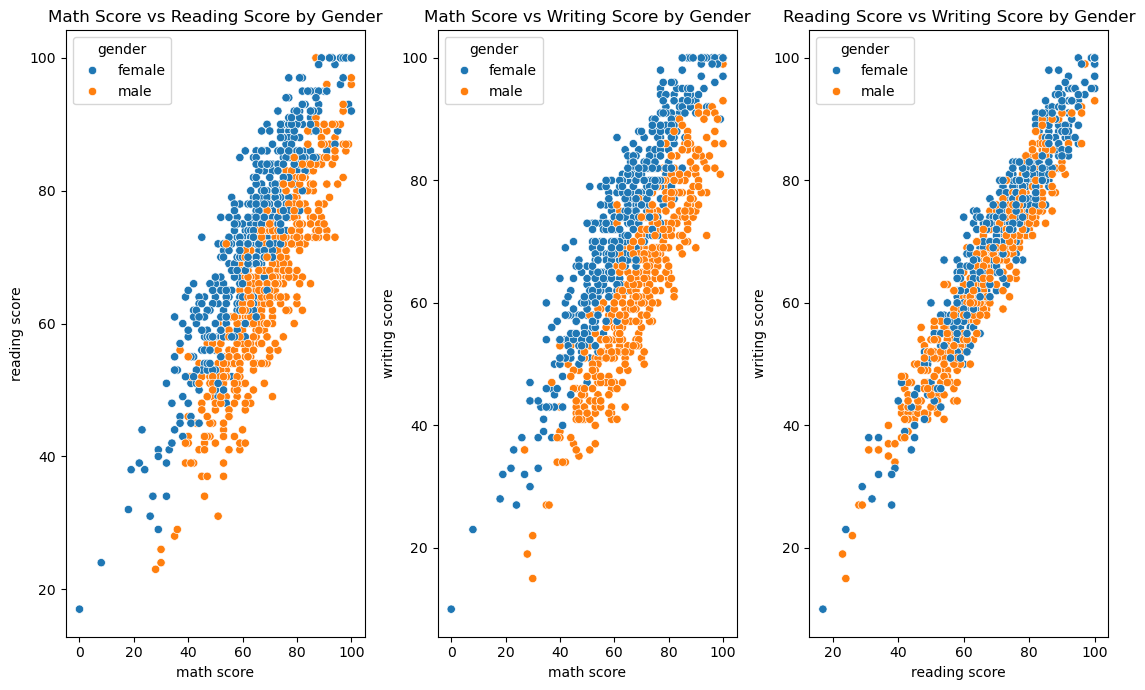

In [131]:
plt.figure(figsize=(15,7))
plt.subplot(1,4,1)
sns.scatterplot(data=df,x='math score',y='reading score',hue='gender')
plt.title('Math Score vs Reading Score by Gender')
plt.subplot(1,4,2)
sns.scatterplot(data=df,x='math score',y='writing score',hue='gender')
plt.title('Math Score vs Writing Score by Gender')
plt.subplot(1,4,3)
sns.scatterplot(data=df,x='reading score',y='writing score',hue='gender')
plt.title('Reading Score vs Writing Score by Gender')


plt.tight_layout()
plt.show()

## Insights 

### 1. Math Score vs Reading Score by Gender
- There is a **strong positive correlation** between math and reading scores — students who perform well in math also tend to perform well in reading.
- **Female students** (blue dots) generally cluster toward higher reading scores compared to males.
- **Male students** (orange dots) show slightly more spread, indicating greater variability in performance.

---

### 2. Math Score vs Writing Score by Gender
- A clear **linear relationship** exists between math and writing scores.
- **Female students** tend to achieve **higher writing scores** for similar math performance levels.
- The distribution suggests that writing ability may be more consistent among females, while males show more variation.

---

### 3. Reading Score vs Writing Score by Gender
- This plot shows the **strongest correlation** among all three — reading and writing scores are almost linearly related.
- Both genders follow a similar trend, but **female students** slightly dominate the upper range of scores.
- This indicates that reading and writing skills are closely linked, and improvement in one likely boosts the other.

---


## 4.4 Multivariate Analysis

### 4.4.1 Test preparation, gender, and average score

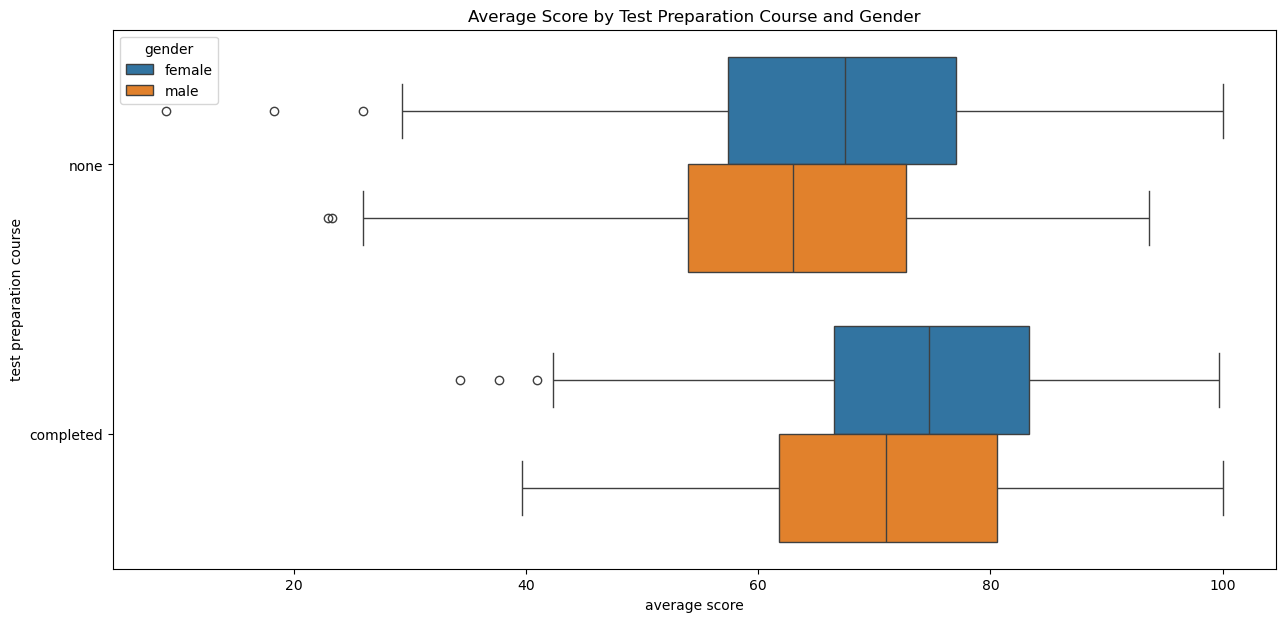

In [132]:
plt.figure(figsize=(15,7))
sns.boxplot(data=df,y='test preparation course',x='average score',hue='gender')
plt.title('Average Score by Test Preparation Course and Gender')
plt.show()

## Insights 

### Average Score by Test Preparation Course and Gender
- Students who **completed the test preparation course** achieved **higher average scores** compared to those who did not.
- The **median score** for both male and female students is noticeably higher in the “completed” group.
- **Female students** (blue boxes) tend to perform slightly better than **male students** (orange boxes) in both categories.
- The **score distribution** for students who completed the course is tighter, indicating more consistent performance.
- Outliers in the “none” group suggest that a few students performed exceptionally well even without preparation, but overall performance is lower.

---


### 4.4.2 Lunch, parental education, and average score

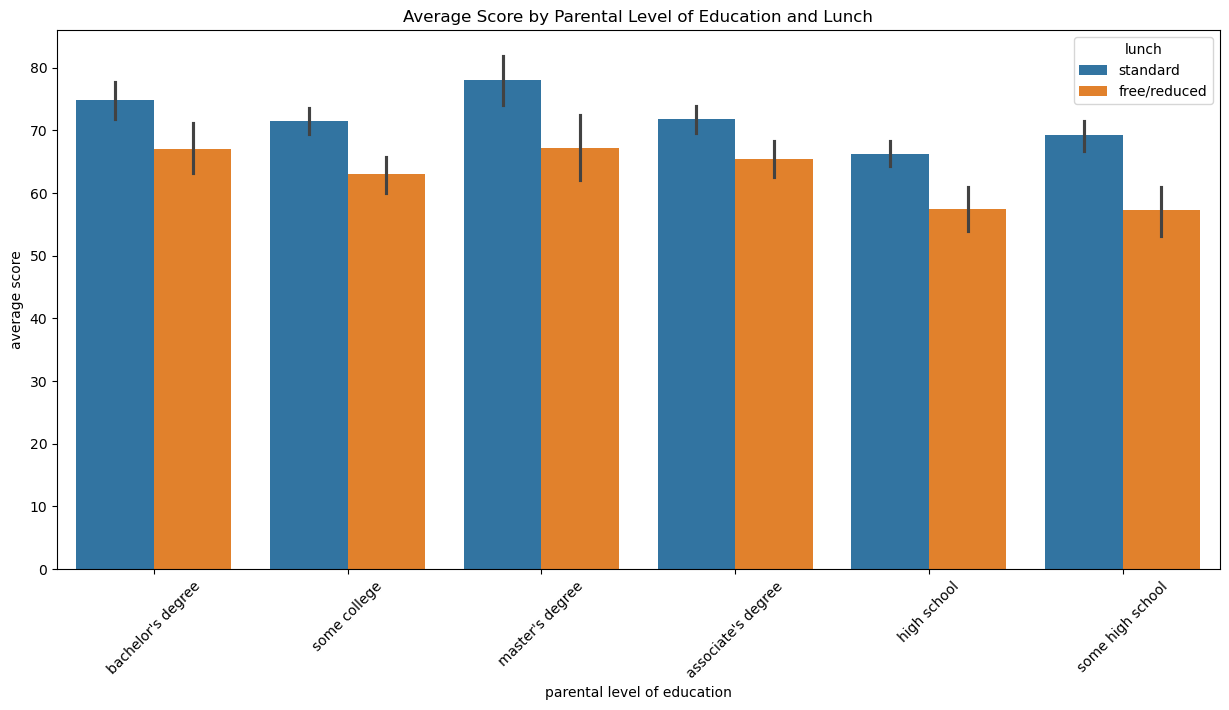

In [133]:
plt.figure(figsize=(15,7))
sns.barplot(data=df,x='parental level of education',y='average score',hue='lunch')
plt.title('Average Score by Parental Level of Education and Lunch')
plt.xticks(rotation=45)
plt.show()

## Insights 

### Average Score by Parental Level of Education and Lunch Type
- Students who receive **standard lunch** consistently achieve **higher average scores** than those with **free/reduced lunch**, across all parental education levels.
- The **highest average scores** are observed among students whose parents hold a **master’s or bachelor’s degree**.
- Students whose parents have **some high school** or **high school** education show the **lowest average scores**, regardless of lunch type.
- The gap between **standard** and **free/reduced lunch** widens as parental education decreases, suggesting that **socioeconomic factors** amplify performance differences.
- The **error bars** indicate that variability in scores is greater among students with lower parental education levels.

---



### 4.4.3 Correlation Heatmap for Reading Score, Writing Score, Math Score, Total Scores and Average Scores

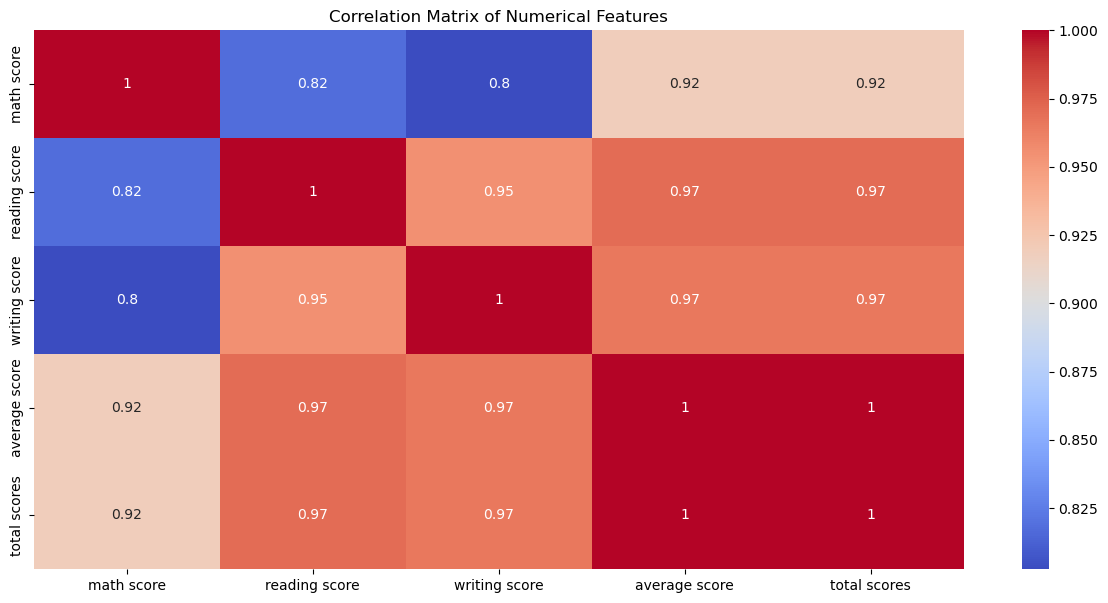

In [134]:
numerical_columns=df.select_dtypes(['int64','float64']).columns.tolist()
correlaction_matrix=df[numerical_columns].corr()
plt.figure(figsize=(15,7))
sns.heatmap(correlaction_matrix,annot=True,cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [135]:

subjects = [
    "math score",
    "reading score",
    "writing score"
]

group_columns = [
    "gender",
    "lunch",
    "test preparation course"
]

for group_col in group_columns:
    summary = (
        df.groupby(group_col)[subjects]
        .agg(["mean", "median", "count"])
        .round(2)
    )

    print(f"\n{'=' * 60}")
    print(f"Student Performance by {group_col.title()}")
    print("=" * 60)

    display(summary)



Student Performance by Gender


math score              reading score              writing score  \
             mean median count          mean median count          mean   
gender                                                                    
female      63.63   65.0   518         72.61   73.0   518         72.47   
male        68.73   69.0   482         65.47   66.0   482         63.31   

                     
       median count  
gender               
female   74.0   518  
male     64.0   482


Student Performance by Lunch


math score              reading score              writing score  \
                   mean median count          mean median count          mean   
lunch                                                                           
free/reduced      58.92   60.0   355         64.65   65.0   355         63.02   
standard          70.03   69.0   645         71.65   72.0   645         70.82   

                           
             median count  
lunch                      
free/reduced   64.0   355  
standard       72.0   645


Student Performance by Test Preparation Course


math score              reading score               \
                              mean median count          mean median count   
test preparation course                                                      
completed                    69.70   69.0   358         73.89   75.0   358   
none                         64.08   64.0   642         66.53   67.0   642   

                        writing score               
                                 mean median count  
test preparation course                             
completed                       74.42   76.0   358  
none                            64.50   65.0   642

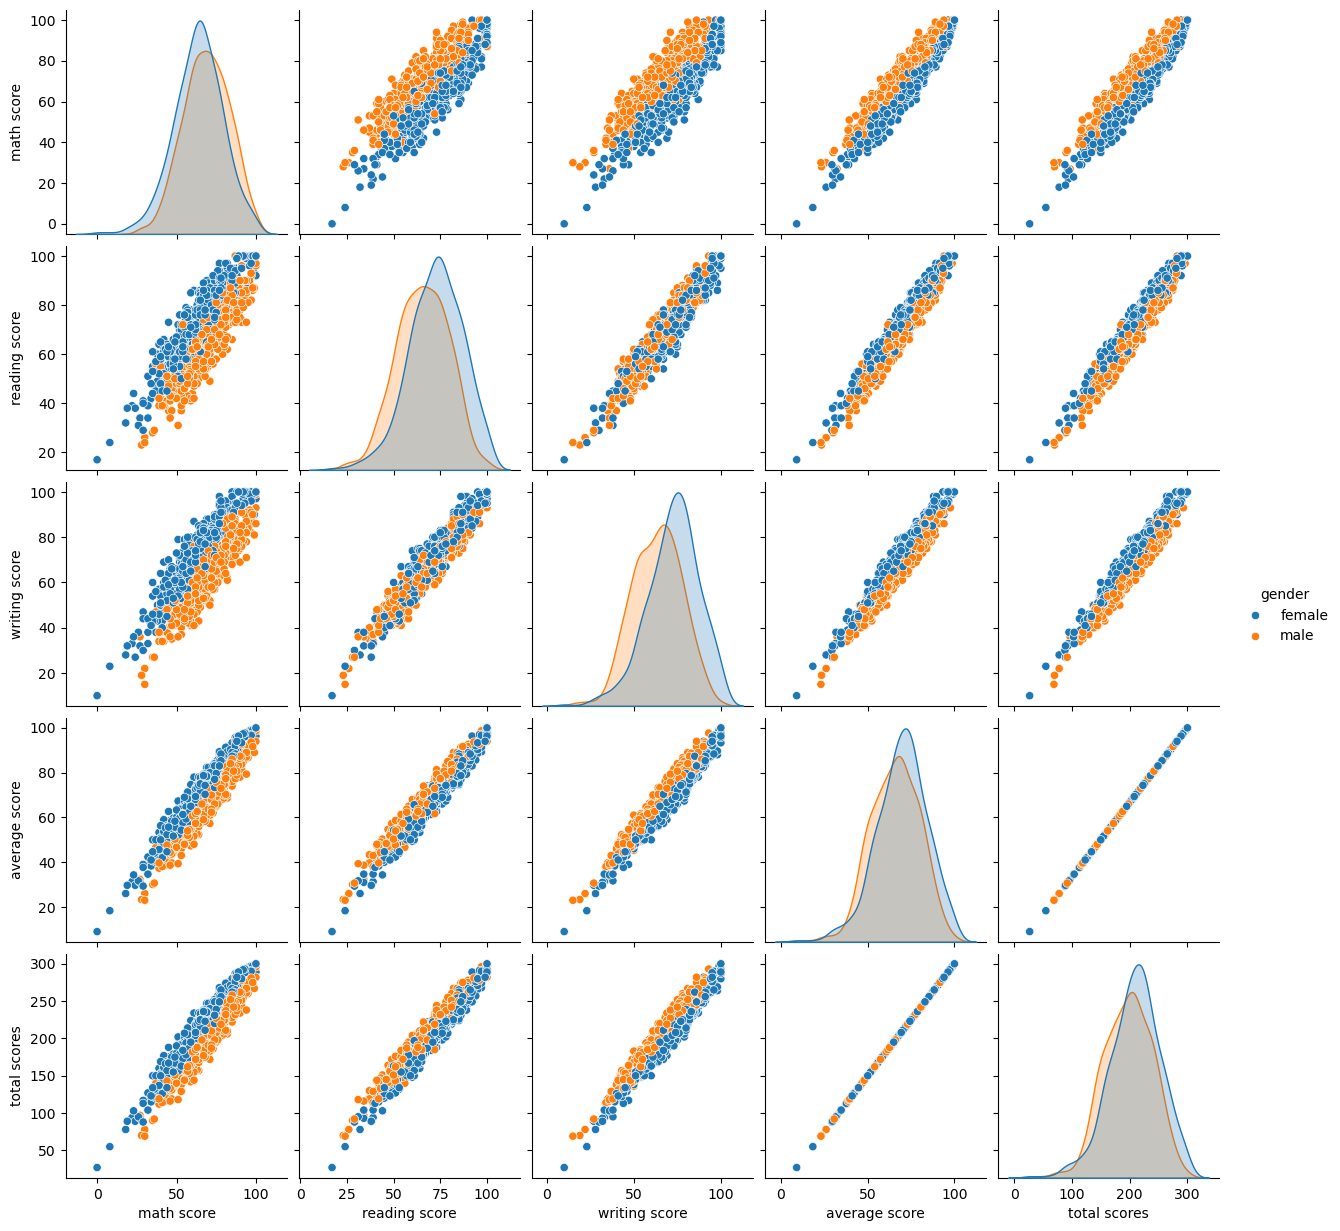

In [136]:
sns.pairplot(df,hue='gender')
plt.show()

## Insights

- From the above plot it is clear that all the scores increases linearly with each other

# Conclusions

- Students performance related to lunch, Parental level of Education and race
- Female Students perform better than Male Student in all the subjects
- Students Performance is not related to test course preparation
- Finishing Preparation course is beneficial for students who are weak in the subjects. 